# 📊 End-to-End YouTube Comments Sentiment Analysis & Indonesian NLP Pipeline
**Author:** Rifasa Hadiarto (UNIKOM)
**Focus:** Data Extraction (API), Text Preprocessing, Slang Normalization, Negation-Aware Sentiment Classification, & Visualization.

---
### 🎯 Tujuan Proyek:
1. **Automated Scraping:** Mengambil komentar publik YouTube secara dinamis via **YouTube Data API v3**.
2. **Indonesian Text Cleaning & Normalization:** Pembersihan regex dan normalisasi singkatan/slang lokal.
3. **Negation-Aware Sentiment Engine:** Klasifikasi sentimen berbasis lexicon dengan penanganan kata negasi (*"tidak bagus"* dihitung negatif, bukan positif).
4. **Visual Analytics:** Distribusi sentimen dan WordCloud kata kunci emosional (tanpa kata hubung/stopwords).

## 1. Import Library & Pengaturan Lingkungan

In [1]:
import os
import re
import getpass
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from googleapiclient.discovery import build

# Konfigurasi gaya visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

print("✅ Library berhasil diimport!")

✅ Library berhasil diimport!


## 2. Autentikasi Aman & Konfigurasi API (No Hardcoded Key)
> **Keamanan:** API Key tidak lagi ditulis terbuka di kode publik. Masukkan API key via prompt terproteksi atau Colab Secrets.

In [2]:
# Cara 1: Ambil dari Colab Secrets (jika sudah disimpan di tab kunci Colab)
try:
    from google.colab import userdata
    API_KEY = userdata.get('YOUTUBE_API_KEY')
except Exception:
    API_KEY = None

# Cara 2: Jika belum di Colab Secrets, gunakan input password terproteksi
if not API_KEY:
    print("🔑 Masukkan YouTube Data API v3 Key Anda (input tersembunyi):")
    API_KEY = getpass.getpass("API Key: ")

# Target Video YouTube (ID video setelah 'v=' pada URL YouTube)
# Contoh URL: https://www.youtube.com/watch?v=TVvc8K8VwNI -> ID: 'TVvc8K8VwNI'
VIDEO_ID = "TVvc8K8VwNI"
MAX_COMMENTS = 500

# Inisialisasi Google API Client
try:
    youtube = build('youtube', 'v3', developerKey=API_KEY)
    print(f"✅ YouTube API Client siap! Target Video ID: {VIDEO_ID} | Maksimal: {MAX_COMMENTS} komentar")
except Exception as e:
    print(f"❌ Inisialisasi API Gagal: {e}")

🔑 Masukkan YouTube Data API v3 Key Anda (input tersembunyi):
API Key: ··········
✅ YouTube API Client siap! Target Video ID: TVvc8K8VwNI | Maksimal: 500 komentar


## 3. Modul Ekstraksi Data (YouTube Scraper with Pagination)

In [3]:
def fetch_youtube_comments(video_id, max_results=500):
    """
    Mengambil komentar dari YouTube Data API v3 dengan pagination otomatis.
    """
    comments_list = []
    next_page_token = None

    print(f"⏳ Memulai ekstraksi data komentar untuk video: {video_id}...")

    while len(comments_list) < max_results:
        try:
            fetch_limit = min(100, max_results - len(comments_list))
            request = youtube.commentThreads().list(
                part="snippet",
                videoId=video_id,
                textFormat="plainText",
                maxResults=fetch_limit,
                pageToken=next_page_token
            )
            response = request.execute()

            for item in response.get("items", []):
                snippet = item["snippet"]["topLevelComment"]["snippet"]
                comments_list.append({
                    "comment_id": item.get("id"),
                    "author": snippet.get("authorDisplayName", "Anonymous"),
                    "comment_text": snippet.get("textDisplay", ""),
                    "like_count": snippet.get("likeCount", 0),
                    "published_at": snippet.get("publishedAt", "")
                })

            next_page_token = response.get("nextPageToken")
            print(f"   -> Terkumpul: {len(comments_list)} komentar...")

            if not next_page_token:
                print("ℹ️ Semua komentar yang tersedia sudah diambil.")
                break

        except Exception as e:
            print(f"⚠️ Peringatan saat scraping: {e}")
            break

    df = pd.DataFrame(comments_list)
    print(f"🎉 Selesai! Berhasil mengekstrak {len(df)} komentar.")
    return df

# Jalankan ekstraksi
df_raw = fetch_youtube_comments(VIDEO_ID, max_results=MAX_COMMENTS)
display(df_raw.head(3))

⏳ Memulai ekstraksi data komentar untuk video: TVvc8K8VwNI...
   -> Terkumpul: 100 komentar...
   -> Terkumpul: 200 komentar...
   -> Terkumpul: 300 komentar...
   -> Terkumpul: 400 komentar...
   -> Terkumpul: 500 komentar...
🎉 Selesai! Berhasil mengekstrak 500 komentar.


,comment_id,author,comment_text,like_count,published_at
0,Ugw999HOOZ_QpEdHDLx4AaABAg,@lvtwilly,Pak Dedi..saya mau masukin anak saya ke barak...,0,2026-10-23T12:35:55Z
1,UgwmbXfiM-Jz_lm_kNx4AaABAg,@MulyadiSah-ij8ls,Saya sangat setuju dan sangat mendukung progra...,1,2026-10-23T07:48:53Z
2,UgwBflHudg4xLub1FBV4AaABAg,@Tjahyono-y9l,"Siap saya dukung KDM ,pemimpin Hebat",0,2026-10-17T07:07:29Z


## 4. Normalisasi Slang & Text Preprocessing Bahasa Indonesia
Di tahap ini teks dibersihkan dari noise (mention, link, simbol) dan kata-kata singkatan gaul (*yg, bgt, mantul*) dinormalisasi.

In [4]:
# Kamus Normalisasi Kata Singkatan & Slang Indonesia
SLANG_MAP = {
    r'\byg\b': 'yang',
    r'\bdgn\b': 'dengan',
    r'\bbgt\b': 'banget',
    r'\bga\b': 'tidak',
    r'\bgak\b': 'tidak',
    r'\bngga\b': 'tidak',
    r'\bnggak\b': 'tidak',
    r'\btak\b': 'tidak',
    r'\bgk\b': 'tidak',
    r'\bbgs\b': 'bagus',
    r'\bmantul\b': 'mantap',
    r'\bsy\b': 'saya',
    r'\bsyuting\b': 'syuting',
    r'\bkrn\b': 'karena',
    r'\bjgn\b': 'jangan',
    r'\btp\b': 'tapi',
    r'\bkpd\b': 'kepada',
    r'\butk\b': 'untuk',
    r'\bsdh\b': 'sudah',
    r'\budh\b': 'sudah',
    r'\bdah\b': 'sudah',
    r'\bblm\b': 'belum'
}

def clean_and_normalize_text(text):
    if pd.isna(text) or not str(text).strip():
        return ""

    text = str(text).lower()
    # Hapus URL
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    # Hapus mention (@username) dan hashtag (#tag)
    text = re.sub(r'[@#]\w+', '', text)
    # Hapus karakter selain huruf dan spasi (membuang emoji/simbol asing)
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Normalisasi kata gaul/singkatan
    for pattern, replacement in SLANG_MAP.items():
        text = re.sub(pattern, replacement, text)

    # Hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Uji fungsi pembersih
test_kalimat = "Videonya bgt bgs & mantul @kdm! tp soundnya ga enak http://link.com"
print(f"Original : {test_kalimat}")
print(f"Cleaned  : {clean_and_normalize_text(test_kalimat)}")

Original : Videonya bgt bgs & mantul @kdm! tp soundnya ga enak http://link.com
Cleaned  : videonya banget bagus mantap tapi soundnya tidak enak


## 5. Mesin Sentimen Cerdas: Penanganan Negasi & Token Matching
### 💡 Logika Peningkatan:
- **Token-based matching:** Menggunakan set token kata utuh, bukan substring (`top` tidak akan cocok lagi dengan `laptop`).
- **Negation Flipping:** Jika kata positif didahului oleh kata negasi (*"tidak", "kurang", "bukan", "belum"*), skor kata tersebut otomatis dibalik menjadi **Negatif**.

In [5]:
# Kosakata Sentimen Positif & Negatif Bahasa Indonesia Terkurasi
POSITIVE_WORDS = {
    'bagus', 'baik', 'hebat', 'keren', 'mantap', 'top', 'suka', 'senang',
    'gembira', 'luar biasa', 'terima kasih', 'makasih', 'motivasi', 'semangat',
    'sehat', 'panjang umur', 'setuju', 'salut', 'moga', 'sukses', 'amanah',
    'inspirasi', 'panutan', 'mulia', 'terbaik', 'cinta', 'berkah', 'lancar',
    'bantu', 'peduli', 'pahlawan', 'bismillah', 'edukatif', 'informatif', 'ramah',
    'bangga', 'respect', 'respek', 'bermanfaat', 'berfaedah', 'pinter', 'cerdas'
}

NEGATIVE_WORDS = {
    'buruk', 'jelek', 'benci', 'sedih', 'marah', 'kecewa', 'menyesal',
    'sampah', 'najis', 'bodoh', 'tolol', 'goblok', 'bangsat', 'sialan',
    'kejam', 'jahat', 'parah', 'bohong', 'hoax', 'pencitraan', 'malas',
    'rugi', 'susah', 'sulit', 'ngeri', 'takut', 'kurang', 'lemah', 'gagal',
    'kasihan', 'rusak', 'curang', 'korupsi', 'kampungan', 'dusta', 'kecewa'
}

# Kata Penyangkal (Negasi)
NEGATION_WORDS = {'tidak', 'bukan', 'kurang', 'jangan', 'belum', 'tak'}

def calculate_sentiment(text):
    """
    Menghitung sentimen teks dengan logika penanganan kata negasi.
    """
    if not text:
        return {'polarity_score': 0.0, 'sentiment': 'Netral', 'pos_words': [], 'neg_words': []}

    words = text.split()
    pos_hits = []
    neg_hits = []

    for i, word in enumerate(words):
        # Periksa apakah 1 atau 2 kata sebelumnya adalah kata negasi
        is_negated = False
        if i > 0 and words[i - 1] in NEGATION_WORDS:
            is_negated = True
        elif i > 1 and words[i - 2] in NEGATION_WORDS:
            is_negated = True

        if word in POSITIVE_WORDS:
            if is_negated:
                neg_hits.append(f"{words[i-1]} {word}")
            else:
                pos_hits.append(word)
        elif word in NEGATIVE_WORDS:
            if is_negated:
                # Contoh: "tidak jelek" -> dihitung positif/netral
                pos_hits.append(f"{words[i-1]} {word}")
            else:
                neg_hits.append(word)

    pos_count = len(pos_hits)
    neg_count = len(neg_hits)

    # Formula polaritas skor terstandarisasi (-1.0 s.d +1.0)
    total = pos_count + neg_count
    if total == 0:
        polarity = 0.0
        label = 'Netral'
    else:
        polarity = (pos_count - neg_count) / total
        if polarity > 0.05:
            label = 'Positif'
        elif polarity < -0.05:
            label = 'Negatif'
        else:
            label = 'Netral'

    return {
        'polarity_score': round(polarity, 3),
        'sentiment': label,
        'pos_words': ", ".join(pos_hits),
        'neg_words': ", ".join(neg_hits)
    }

# Uji Penanganan Negasi vs Kalimat Biasa
test_cases = [
    "Program ini sangat bagus dan menginspirasi",
    "Program ini tidak bagus dan sangat membosankan",  # Uji Negasi
    "Pelayanannya kurang mantap",                      # Uji Negasi
    "Laptop saya baru dibeli"                          # Kata 'top' di laptop tidak boleh jadi positif
]
print("🔬 HASIL UJI COBA MESIN SENTIMEN BARU:")
for t in test_cases:
    res = calculate_sentiment(clean_and_normalize_text(t))
    print(f"Kalimat: '{t}' -> [{res['sentiment']}] (Skor: {res['polarity_score']})")

🔬 HASIL UJI COBA MESIN SENTIMEN BARU:
Kalimat: 'Program ini sangat bagus dan menginspirasi' -> [Positif] (Skor: 1.0)
Kalimat: 'Program ini tidak bagus dan sangat membosankan' -> [Negatif] (Skor: -1.0)
Kalimat: 'Pelayanannya kurang mantap' -> [Negatif] (Skor: -1.0)
Kalimat: 'Laptop saya baru dibeli' -> [Netral] (Skor: 0.0)


## 6. Eksekusi Analisis pada Seluruh Komentar YouTube

In [6]:
# 1. Bersihkan teks
df_raw['clean_text'] = df_raw['comment_text'].apply(clean_and_normalize_text)

# 2. Hitung sentimen untuk tiap komentar
print("⚡ Menganalisis sentimen seluruh komentar...")
sentiment_metrics = df_raw['clean_text'].apply(calculate_sentiment).apply(pd.Series)

# 3. Gabungkan ke DataFrame final
df_final = pd.concat([df_raw, sentiment_metrics], axis=1)

# Ringkasan Hasil
print("\n📈 DISTRIBUSI SENTIMEN KOMENTAR:")
summary = df_final['sentiment'].value_counts()
for s, count in summary.items():
    pct = (count / len(df_final)) * 100
    print(f"  • {s:7s}: {count:4d} komentar ({pct:.1f}%)")

display(df_final[['author', 'comment_text', 'sentiment', 'polarity_score', 'like_count']].head(5))

⚡ Menganalisis sentimen seluruh komentar...

📈 DISTRIBUSI SENTIMEN KOMENTAR:
  • Netral :  285 komentar (57.0%)
  • Positif:  193 komentar (38.6%)
  • Negatif:   22 komentar (4.4%)


,author,comment_text,sentiment,polarity_score,like_count
0,@lvtwilly,Pak Dedi..saya mau masukin anak saya ke barak...,Netral,0.0,0
1,@MulyadiSah-ij8ls,Saya sangat setuju dan sangat mendukung progra...,Positif,1.0,1
2,@Tjahyono-y9l,"Siap saya dukung KDM ,pemimpin Hebat",Positif,1.0,0
3,@EnokSyamsiyah,Asslmalaikm ciwalen ciamis jabar hadir,Netral,0.0,0
4,@UndangLutfi-c9g,Mantap bapak kdm maju terus 💪,Positif,1.0,0


## 7. Visualisasi Hasil (Distribution & High-Quality WordCloud)
Menghilangkan kata hubung (*stopwords*) bahasa Indonesia agar WordCloud hanya menampilkan kata bermakna.

/tmp/ipykernel_3775/3231124595.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df_final, x='sentiment', order=['Positif', 'Netral', 'Negatif'], palette=palette_colors, ax=ax1)


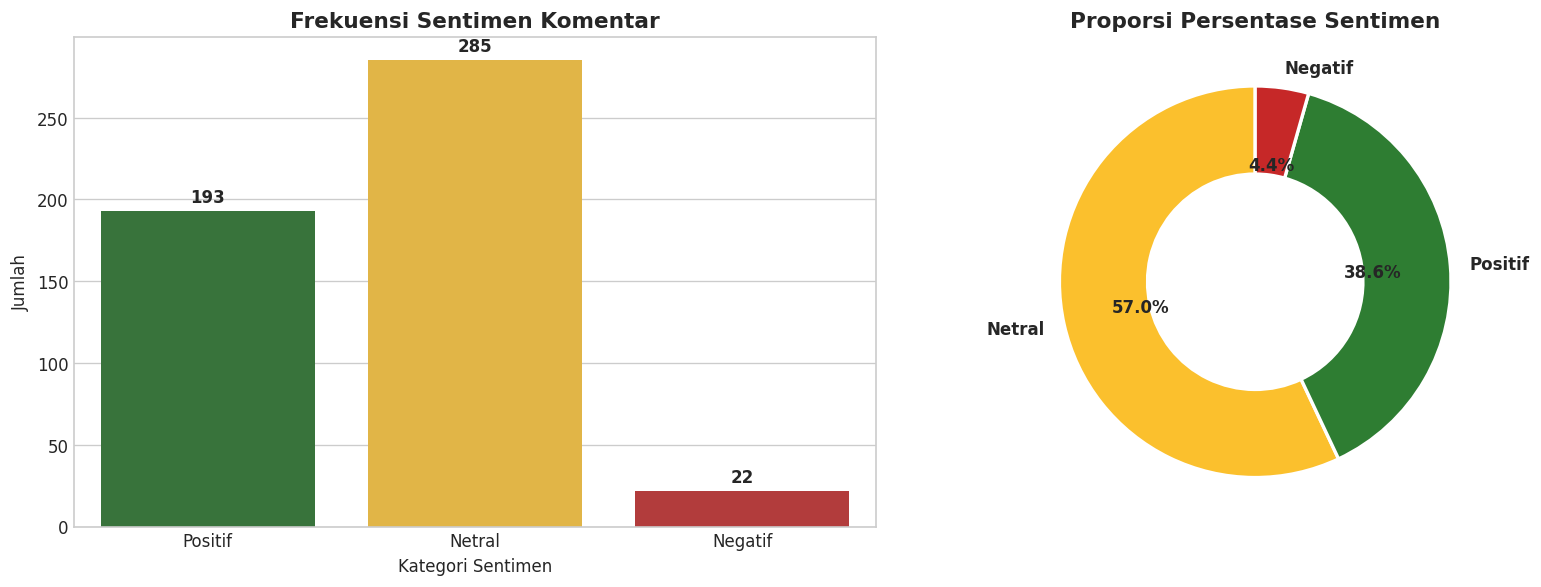

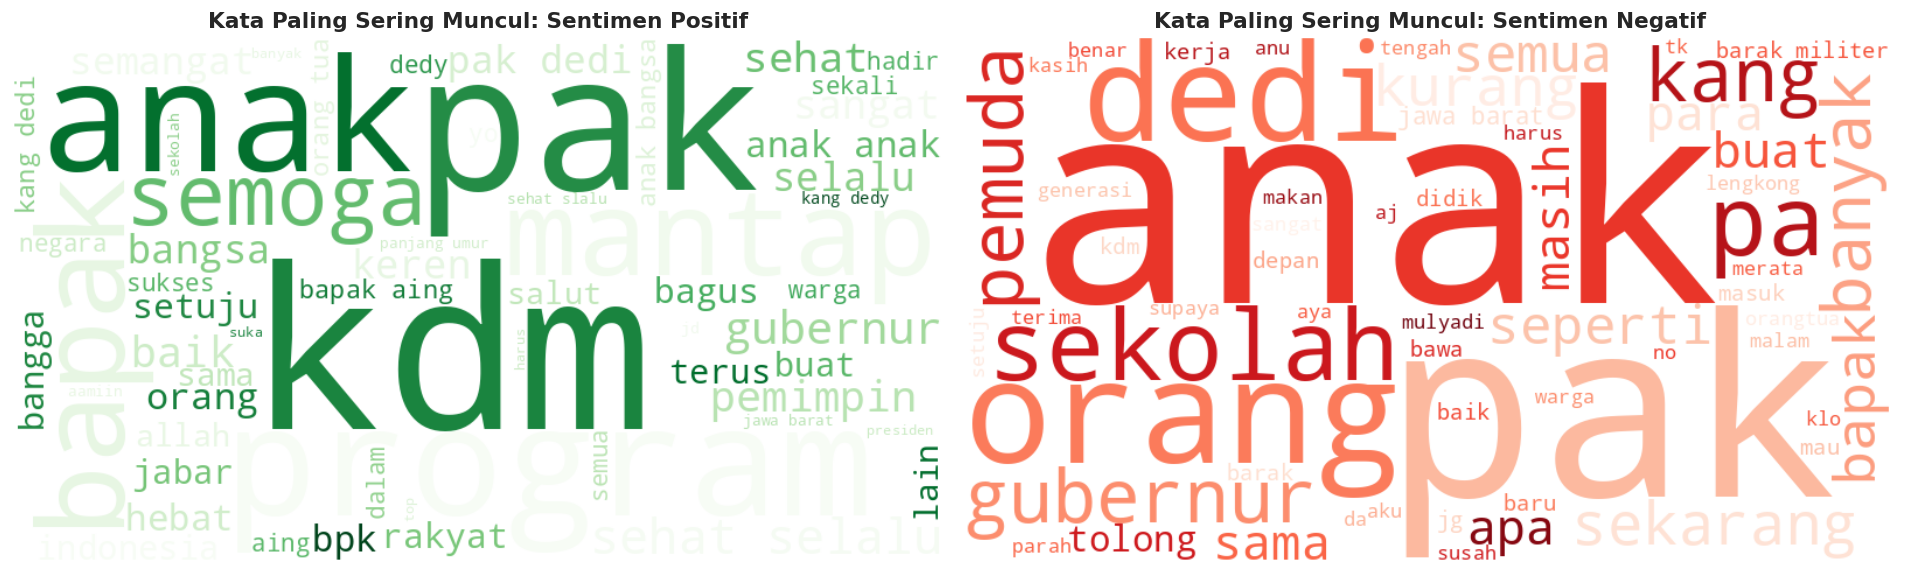

In [7]:
# 1. Visualisasi Proporsi & Jumlah Sentimen
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
palette_colors = {'Positif': '#2e7d32', 'Netral': '#fbc02d', 'Negatif': '#c62828'}

# Bar Plot
sns.countplot(data=df_final, x='sentiment', order=['Positif', 'Netral', 'Negatif'], palette=palette_colors, ax=ax1)
ax1.set_title("Frekuensi Sentimen Komentar", fontsize=13, fontweight='bold')
ax1.set_xlabel("Kategori Sentimen")
ax1.set_ylabel("Jumlah")
for p in ax1.patches:
    ax1.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 3), textcoords='offset points')

# Donut Pie Chart
counts = df_final['sentiment'].value_counts()
pie_colors = [palette_colors.get(k, '#9e9e9e') for k in counts.index]
ax2.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90, colors=pie_colors,
        wedgeprops=dict(width=0.45, edgecolor='w', linewidth=2), textprops={'fontweight': 'bold'})
ax2.set_title("Proporsi Persentase Sentimen", fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

# 2. WordCloud dengan Filter Stopwords Bahasa Indonesia
INDONESIAN_STOPWORDS = {
    'yang', 'di', 'dan', 'ini', 'itu', 'dari', 'ke', 'pada', 'untuk', 'dengan',
    'adalah', 'ada', 'bisa', 'akan', 'sudah', 'saya', 'kamu', 'dia', 'mereka',
    'kita', 'kami', 'karena', 'oleh', 'saat', 'jika', 'agar', 'atau', 'tapi',
    'juga', 'hanya', 'saja', 'bukan', 'tidak', 'lagi', 'sudah', 'lebih', 'jadi',
    'kalo', 'kalau', 'kok', 'sih', 'nih', 'dong', 'nya', 'ya', 'kan'
}

pos_texts = " ".join(df_final[df_final['sentiment'] == 'Positif']['clean_text'])
neg_texts = " ".join(df_final[df_final['sentiment'] == 'Negatif']['clean_text'])

fig, (ax_pos, ax_neg) = plt.subplots(1, 2, figsize=(16, 7))

if pos_texts.strip():
    wc_pos = WordCloud(width=800, height=450, background_color='white', colormap='Greens',
                       stopwords=INDONESIAN_STOPWORDS, max_words=60).generate(pos_texts)
    ax_pos.imshow(wc_pos, interpolation='bilinear')
    ax_pos.set_title("Kata Paling Sering Muncul: Sentimen Positif", fontsize=13, fontweight='bold')
    ax_pos.axis('off')
else:
    ax_pos.text(0.5, 0.5, 'Tidak ada teks positif', ha='center')
    ax_pos.axis('off')

if neg_texts.strip():
    wc_neg = WordCloud(width=800, height=450, background_color='white', colormap='Reds',
                       stopwords=INDONESIAN_STOPWORDS, max_words=60).generate(neg_texts)
    ax_neg.imshow(wc_neg, interpolation='bilinear')
    ax_neg.set_title("Kata Paling Sering Muncul: Sentimen Negatif", fontsize=13, fontweight='bold')
    ax_neg.axis('off')
else:
    ax_neg.text(0.5, 0.5, 'Tidak ada teks negatif', ha='center')
    ax_neg.axis('off')

plt.tight_layout()
plt.show()

## 8. Export Hasil Bersih ke File CSV

In [8]:
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
output_filename = f"youtube_sentiment_kdm_{VIDEO_ID}_{timestamp}.csv"

# Pilih kolom-kolom penting yang bersih
columns_to_export = [
    'comment_id', 'author', 'published_at', 'like_count',
    'comment_text', 'clean_text', 'sentiment', 'polarity_score',
    'pos_words', 'neg_words'
]

df_final[columns_to_export].to_csv(output_filename, index=False, encoding='utf-8')
print(f"💾 File hasil analisis bersih berhasil disimpan ke: '{output_filename}'")
print(f"   Total baris: {len(df_final)} data siap pakai!")

💾 File hasil analisis bersih berhasil disimpan ke: 'youtube_sentiment_kdm_TVvc8K8VwNI_20261024_085542.csv'
   Total baris: 500 data siap pakai!
